In [2]:
%pip install -q tensorflow keras pandas scikit-learn matplotlib seaborn visualkeras

# Module 4.1 Assignment - CNNs vs. Transformers

> Submitted by Phillip Amir Esguerra

# 1. Loading CIFAR-10 dataset

In [3]:
from keras.activations import gelu
from keras.callbacks import ModelCheckpoint
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Normalization, Resizing, RandomFlip, RandomRotation, RandomZoom, Dropout
from keras.optimizers import Adam, AdamW
from keras.losses import SparseCategoricalCrossentropy
from keras.metrics import SparseCategoricalAccuracy, SparseTopKCategoricalAccuracy
from keras.datasets import cifar10
from keras import Input, Model, layers, ops
from sklearn.model_selection import train_test_split
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import visualkeras
import pandas as pd

In [4]:
cifar10_data = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step


# 2. Exploratory Data Analysis

In [5]:
(x_train, y_train), (x_test, y_test) = cifar10_data

print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}, y_test shape: {y_test.shape}")

x_train shape: (50000, 32, 32, 3), y_train shape: (50000, 1)
x_test shape: (10000, 32, 32, 3), y_test shape: (10000, 1)


In [6]:
# labels based on description
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
class_name_len = len(class_names)


/tmp/ipython-input-764069537.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train.flatten(), palette="coolwarm", ax=axes[0])
/tmp/ipython-input-764069537.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(class_names, rotation=45)
/tmp/ipython-input-764069537.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_test.flatten(), palette="coolwarm", ax=axes[1])
/tmp/ipython-input-764069537.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(class_names, rotation=

[Text(0, 0, 'airplane'),
 Text(1, 0, 'automobile'),
 Text(2, 0, 'bird'),
 Text(3, 0, 'cat'),
 Text(4, 0, 'deer'),
 Text(5, 0, 'dog'),
 Text(6, 0, 'frog'),
 Text(7, 0, 'horse'),
 Text(8, 0, 'ship'),
 Text(9, 0, 'truck')]

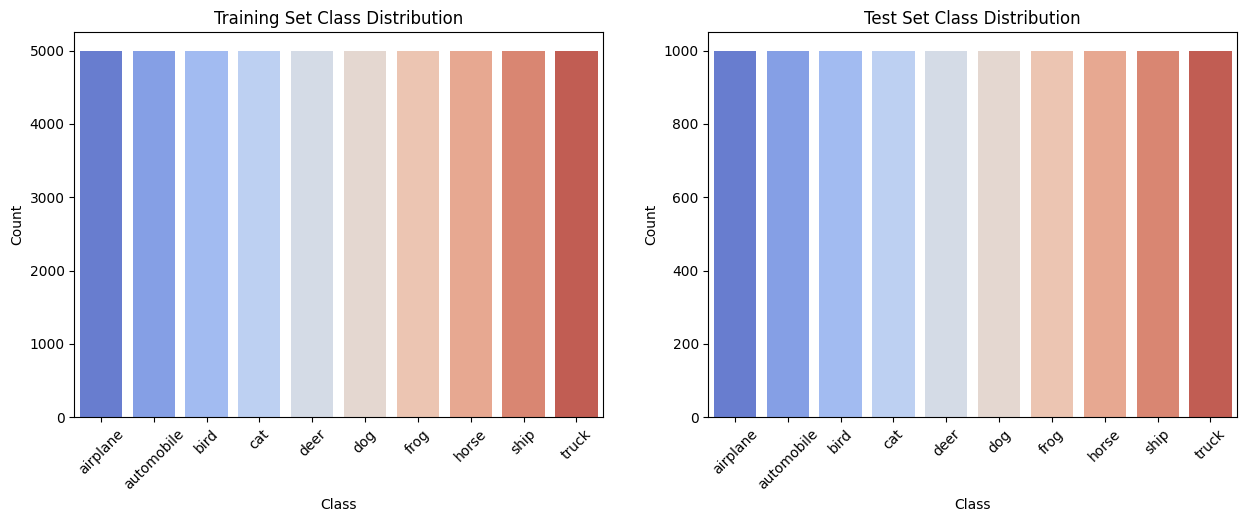

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(x=y_train.flatten(), palette="coolwarm", ax=axes[0])
axes[0].set_title("Training Set Class Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(class_names, rotation=45)

sns.countplot(x=y_test.flatten(), palette="coolwarm", ax=axes[1])
axes[1].set_title("Test Set Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Count")
axes[1].set_xticklabels(class_names, rotation=45)

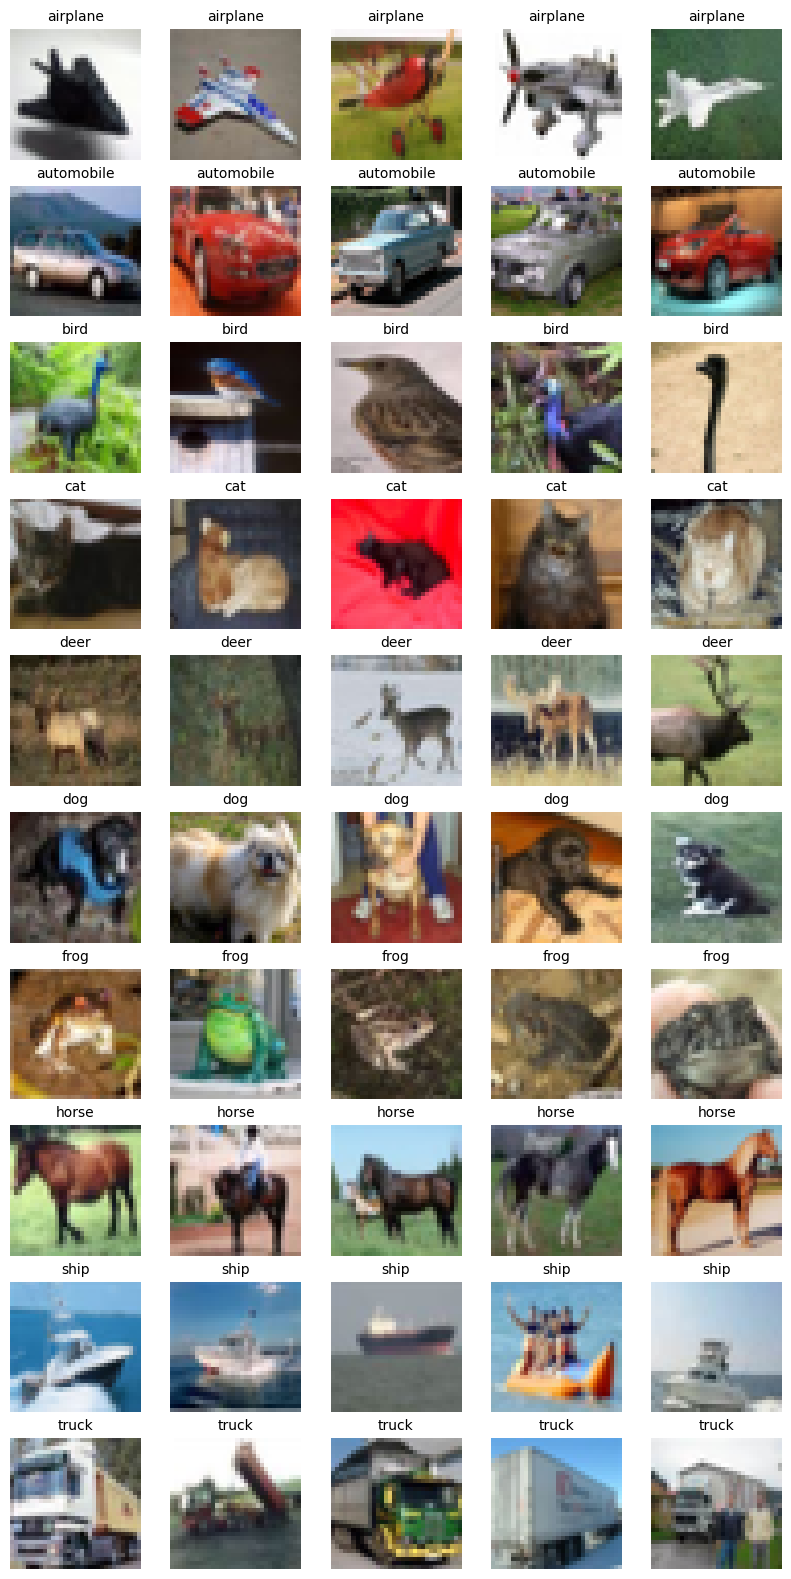

In [8]:
fig, axes = plt.subplots(class_name_len, 5, figsize=(10, 20))

for i, label in enumerate(class_names):
    class_indices = np.where(y_train.flatten() == i)[0]
    for j in range(5):
        axes[i, j].imshow(x_train[class_indices[j]])
        axes[i, j].set_title(f"{label}", fontsize=10)
        axes[i, j].axis('off')

plt.show()

# 3. Checking for Data Quality

In [20]:

image_shape = (32, 32, 3)
print(image_shape)

all_same_shape = all(image.shape == image_shape for image in x_train)
print(f"All images in x_train have the same size: {all_same_shape}")

all_same_shape = all(image.shape == image_shape for image in x_test)
print(f"All images in x_test have the same size: {all_same_shape}")

(32, 32, 3)
All images in x_train have the same size: True
All images in x_test have the same size: True


In [21]:
print("Null values in x_train:", np.isnan(x_train).sum())
print("Null values in y_train:", np.isnan(y_train).sum())
print("Null values in x_test:", np.isnan(x_test).sum())
print("Null values in y_test:", np.isnan(y_test).sum())

Null values in x_train: 0
Null values in y_train: 0
Null values in x_test: 0
Null values in y_test: 0


# 4. CNN Model

In [22]:
def create_cnn_model():
    model = Sequential()
    model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
    model.add(MaxPool2D((2, 2)))
    model.add(Conv2D(64, (3, 3), activation='relu'))
    model.add(MaxPool2D((2, 2)))
    model.add(Conv2D(64, (3, 3), activation='relu'))
    model.add(Flatten())
    model.add(Dense(512, activation = "relu"))
    model.add(Dense(256, activation = "relu"))
    model.add(Dense(128, activation = "relu"))
    model.add(Dense(10, activation = "softmax"))

    return model

In [23]:
test_images, val_images, test_labels, val_labels = train_test_split(x_test, y_test, test_size=0.2, random_state=42)

# 5. Model Training

In [41]:
def plot_history(history, item):
    plt.plot(history.history[item], label=item)
    plt.plot(history.history["val_" + item], label="val_" + item)
    plt.xlabel("Epochs")
    plt.ylabel(item)
    plt.title("Train and Validation {} Over Epochs".format(item), fontsize=14)
    plt.legend()
    plt.grid()
    plt.show()

def plot_history_2(history, item1, item2):
    figure, axes = plt.subplots(1,2, figsize=(15, 5))
    axes = axes.flatten()

    axes[0].plot(history.history[item1], label=item1)
    axes[0].plot(history.history["val_" + item1], label="val_" + item1)
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel(item1)
    axes[0].set_title("Train and Validation {} Over Epochs".format(item1))

    axes[1].plot(history.history[item2], label=item2)
    axes[1].plot(history.history["val_" + item2], label="val_" + item2)
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel(item2)
    axes[1].set_title("Train and Validation {} Over Epochs".format(item2))

In [25]:
learning_rate = 0.001
weight_decay = 0.0001

batch_size = 256
num_epochs = 100

In [26]:
def run_experiment(model, name):
    optimizer = AdamW(
        learning_rate=learning_rate, weight_decay=weight_decay
    )

    model.compile(
        optimizer=optimizer,
        loss=SparseCategoricalCrossentropy(from_logits=True),
        metrics=[
            SparseCategoricalAccuracy(name="accuracy"),
            SparseTopKCategoricalAccuracy(5, name="top-5-accuracy"),
        ])

    checkpoint_filepath = f"/tmp/{name}_checkpoint.weights.h5"
    checkpoint_callback = ModelCheckpoint(
        checkpoint_filepath,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
    )

    history = model.fit(
        x=x_train,
        y=y_train,
        batch_size=batch_size,
        epochs=num_epochs,
        validation_split=0.1,
        callbacks=[checkpoint_callback],
    )

    model.load_weights(checkpoint_filepath)
    _, accuracy, top_5_accuracy = model.evaluate(x_test, y_test)
    print(f"Test accuracy: {round(accuracy * 100, 2)}%")
    print(f"Test top 5 accuracy: {round(top_5_accuracy * 100, 2)}%")

    return history

In [27]:
cnn_model = create_cnn_model()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [28]:
cnn_history = run_experiment(cnn_model, "CNN")

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/nn.py:717: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


176/176 ━━━━━━━━━━━━━━━━━━━━ 37s 120ms/step - accuracy: 0.2533 - loss: 4.4157 - top-5-accuracy: 0.7235 - val_accuracy: 0.4640 - val_loss: 1.5004 - val_top-5-accuracy: 0.9144
Epoch 2/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4776 - loss: 1.4422 - top-5-accuracy: 0.9221 - val_accuracy: 0.5438 - val_loss: 1.2946 - val_top-5-accuracy: 0.9416
Epoch 3/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5470 - loss: 1.2638 - top-5-accuracy: 0.9432 - val_accuracy: 0.5840 - val_loss: 1.1959 - val_top-5-accuracy: 0.9512
Epoch 4/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6038 - loss: 1.1132 - top-5-accuracy: 0.9588 - val_accuracy: 0.6198 - val_loss: 1.0916 - val_top-5-accuracy: 0.9566
Epoch 5/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6508 - loss: 0.9911 - top-5-accuracy: 0.9670 - val_accuracy: 0.6270 - val_loss: 1.0967 - val_top-5-accuracy: 0.9636
Epoch 6/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6856 - loss: 0.8860 - top-5

# 6. Model Architecture and Training Progress

## Model Summary

In [29]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,239,904 (8.54 MB)

 Trainable params: 746,634 (2.85 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,493,270 (5.70 MB)

/usr/local/lib/python3.11/dist-packages/visualkeras/layered.py:86: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


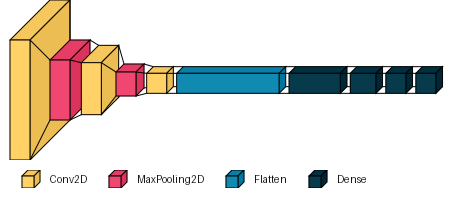

In [30]:
visualkeras.layered_view(cnn_model, legend=True)

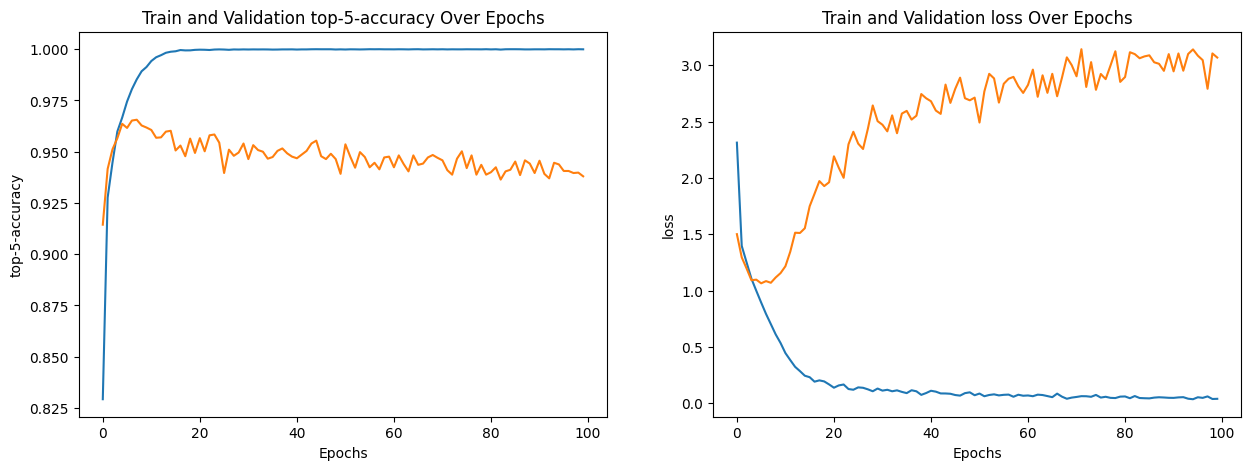

In [42]:
plot_history_2(cnn_history, "top-5-accuracy", "loss")

# 7. ViT Model

In [43]:
num_classes = 10
input_shape = (32, 32, 3)

image_size = 72
patch_size = 6
num_patches = (image_size // patch_size) ** 2
projection_dim = 64
num_heads = 4
transformer_units = [
    projection_dim * 2,
    projection_dim,
]
transformer_layers = 8
mlp_head_units = [
    2048,
    1024,
]

In [44]:
def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = Dense(units, activation=gelu)(x)
        x = Dropout(dropout_rate)(x)
    return x

In [45]:
class Patches(layers.Layer):
    def __init__(self, patch_size):
        super().__init__()
        self.patch_size = patch_size

    def call(self, images):
        input_shape = ops.shape(images)
        batch_size = input_shape[0]
        height = input_shape[1]
        width = input_shape[2]
        channels = input_shape[3]
        num_patches_h = height // self.patch_size
        num_patches_w = width // self.patch_size
        patches = ops.image.extract_patches(images, size=self.patch_size)
        patches = ops.reshape(
            patches,
            (
                batch_size,
                num_patches_h * num_patches_w,
                self.patch_size * self.patch_size * channels,
            ),
        )
        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config

In [47]:
class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super().__init__()
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )

    def call(self, patch):
        positions = ops.expand_dims(
            ops.arange(start=0, stop=self.num_patches, step=1), axis=0
        )
        projected_patches = self.projection(patch)
        encoded = projected_patches + self.position_embedding(positions)
        return encoded

    def get_config(self):
        config = super().get_config()
        config.update({"num_patches": self.num_patches})
        return config

In [48]:
def create_vit_classifier():
    inputs = Input(shape=input_shape)
    data_augmentation = Sequential(
        [
            Normalization(),
            Resizing(image_size, image_size),
            RandomFlip("horizontal"),
            RandomRotation(factor=0.02),
            RandomZoom(height_factor=0.2, width_factor=0.2),
        ],
        name="data_augmentation",
    )
    data_augmentation.layers[0].adapt(x_train)
    augmented = data_augmentation(inputs)
    patches = Patches(patch_size)(augmented)
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    for _ in range(transformer_layers):
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.1
        )(x1, x1)
        x2 = layers.Add()([attention_output, encoded_patches])
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.1)
        encoded_patches = layers.Add()([x3, x2])

    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.Flatten()(representation)
    representation = layers.Dropout(0.5)(representation)
    features = mlp(representation, hidden_units=mlp_head_units, dropout_rate=0.5)
    logits = layers.Dense(num_classes)(features)
    model = Model(inputs=inputs, outputs=logits)
    return model

# 8. ViT Model Training

In [51]:
vit_classifier = create_vit_classifier()

In [ ]:
vit_history = run_experiment(vit_classifier, "ViT")

Epoch 1/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 75s 261ms/step - accuracy: 0.2506 - loss: 2.7233 - top-5-accuracy: 0.7426 - val_accuracy: 0.4504 - val_loss: 1.5361 - val_top-5-accuracy: 0.9076
Epoch 2/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 44s 251ms/step - accuracy: 0.4166 - loss: 1.6125 - top-5-accuracy: 0.8864 - val_accuracy: 0.5278 - val_loss: 1.2948 - val_top-5-accuracy: 0.9448
Epoch 3/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 44s 252ms/step - accuracy: 0.4891 - loss: 1.4199 - top-5-accuracy: 0.9234 - val_accuracy: 0.5608 - val_loss: 1.2129 - val_top-5-accuracy: 0.9484
Epoch 4/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 44s 251ms/step - accuracy: 0.5240 - loss: 1.3360 - top-5-accuracy: 0.9326 - val_accuracy: 0.6176 - val_loss: 1.0853 - val_top-5-accuracy: 0.9602
Epoch 5/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 44s 251ms/step - accuracy: 0.5596 - loss: 1.2447 - top-5-accuracy: 0.9419 - val_accuracy: 0.6386 - val_loss: 1.0095 - val_top-5-accuracy: 0.9706
Epoch 6/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 43s 246ms/step - accuracy: 0.

# 9. ViT Model Architecture and Training Progress

In [ ]:
vit_classifier.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 72, 72, 3) │          7 │ input_layer_1[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches_1 (Patches) │ (None, 144, 108)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 144, 64)   │     16,192 │ patches_1[0][0]   │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 144, 64)   │        128 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 144, 64)   │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 144, 64)   │          0 │ multi_head_atten… │
│                     │                   │            │ patch_encoder[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 144, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 144, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 144, 128)  │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 144, 64)   │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 144, 64)   │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 144, 64)   │          0 │ dropout_2[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 144, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 144, 64)   │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 144, 64)   │          0 │ multi_head_atten… │
│                     │                   │            │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 144, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 144, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 144, 128)  │          0 │ dense_7[0][0]   

 Total params: 65,000,295 (247.96 MB)

 Trainable params: 21,666,762 (82.65 MB)

 Non-trainable params: 7 (32.00 B)

 Optimizer params: 43,333,526 (165.30 MB)

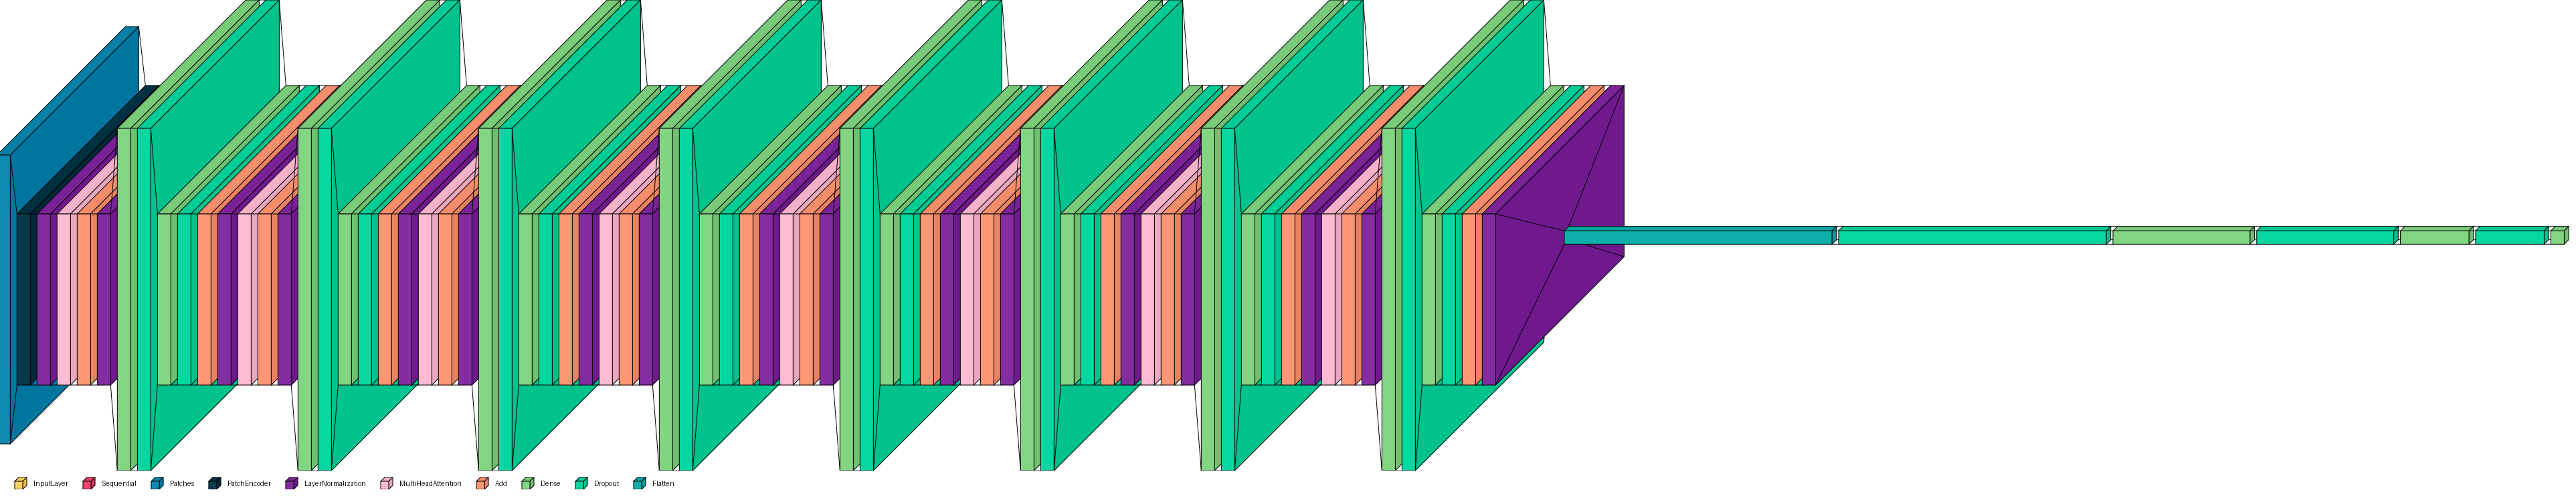

In [ ]:
visualkeras.layered_view(vit_classifier, legend=True)

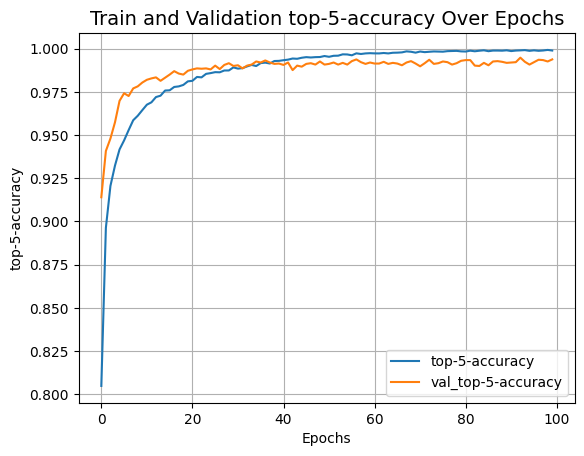

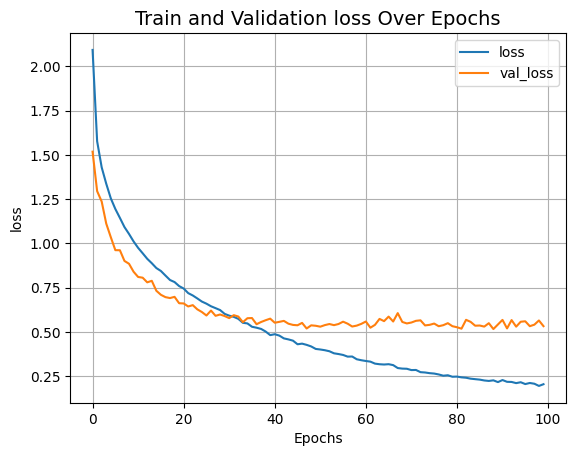

In [ ]:
plot_history(vit_history, "top-5-accuracy")
plot_history(vit_history, "loss")

# 10. CNN vs ViT